# Assignment 7 - Hindi POS Tagging with HMM

HMM-based part-of-speech tagging for Hindi using the Viterbi algorithm variants from SLP Chapter 5. Train an HMM on the Hindi POS training data, then implement forward Viterbi, backward Viterbi, and forward-backward Viterbi decoding and evaluate on dev and test sets with per-tag F1.

In [2]:
import os
import math
import pickle
from collections import Counter, defaultdict

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Imports and setup

Create output directories for models and results.

In [3]:
START = "<s>"
END = "</s>"

def read_pos_file(path):
    sentences_words = []
    sentences_tags = []
    current_words = []
    current_tags = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_words:
                    sentences_words.append(current_words)
                    sentences_tags.append(current_tags)
                    current_words = []
                    current_tags = []
                continue
            parts = line.split()
            if len(parts) >= 2:
                word = parts[0]
                tag = parts[-1]
                current_words.append(word)
                current_tags.append(tag)
    if current_words:
        sentences_words.append(current_words)
        sentences_tags.append(current_tags)
    return sentences_words, sentences_tags


train_words, train_tags = read_pos_file(
    "Hindi-POS-Data/hindi-train-pos.txt"
)
dev_words, dev_tags = read_pos_file(
    "Hindi-POS-Data/hindi-dev-pos.txt"
)
test_words, test_tags = read_pos_file(
    "Hindi-POS-Data/hindi-test-pos.txt"
)


print("Train sentences:", len(train_words))
print("Dev sentences:", len(dev_words))
print("Test sentences:", len(test_words))

Train sentences: 15087
Dev sentences: 1866
Test sentences: 1910


## Data loading

Read the Hindi POS tagged files (one word/tag pair per line, blank line = sentence boundary) for train, dev and test splits, and report counts.

In [4]:
train_tagged = [
    (w, t)
    for words, tags in zip(train_words, train_tags)
    for w, t in zip(words, tags)
]


words_set = set()
tags_set = set()
for w, t in train_tagged:
    words_set.add(w)
    tags_set.add(t)


word2idx = {w: i for i, w in enumerate(sorted(words_set))}
idx2word = {i: w for w, i in word2idx.items()}
tag2idx = {t: i for i, t in enumerate(sorted(tags_set))}
idx2tag = {i: t for t, i in tag2idx.items()}


vocab_size = len(words_set)
num_tags = len(tags_set)


print("Vocab size:", vocab_size)
print("Num tags:", num_tags)
print("Tags:", sorted(tags_set))

Vocab size: 18279
Num tags: 24
Tags: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']


# Naive Bayes Word Classifier

Word-level Naive Bayes part-of-speech classifier following the assignment specification. For each word we extract five features: word length binary (MORE if length > 4 else LESS), the actual word, the previous word, the next word, and the previous tag. We train on the Hindi training data and evaluate per-token tagging accuracy and per-tag F1.

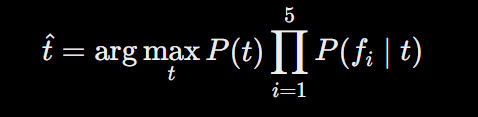

In [5]:
import numpy as np
from math import log


def word_length_feat(w):
    return "MORE" if len(w) > 4 else "LESS"


def ngrams(words, tags):
    prev_words = ["<s>"] + words[:-1]
    next_words = words[1:] + ["</s>"]
    prev_tags = ["<s>"] + tags[:-1]
    return prev_words, next_words, prev_tags


def nb_feature_tuples(words, tags):
    prev_words, next_words, prev_tags = ngrams(words, tags)
    feats = []
    for i, w in enumerate(words):
        feat = (
            word_length_feat(w),
            w,
            prev_words[i],
            next_words[i],
            prev_tags[i],
        )
        feats.append((feat, tags[i]))
    return feats


train_nb = []
for words, tags in zip(train_words, train_tags):
    train_nb.extend(nb_feature_tuples(words, tags))


NB_PRIOR_SMOOTH = 1.0
NB_LIKELIHOOD_SMOOTH = 1.0


nb_tag_counts = Counter()
nb_feat_cond_counts = defaultdict(Counter)


for feat, tag in train_nb:
    nb_tag_counts[tag] += 1
    for f in feat:
        nb_feat_cond_counts[tag][f] += 1


nb_tag_total = sum(nb_tag_counts.values())
nb_num_tags = len(nb_tag_counts)


nb_feat_vocabs = {}
for tag in sorted(nb_tag_counts):
    nb_feat_vocabs[tag] = {}
    for i in range(5):
        nb_feat_vocabs[tag][i] = len(nb_feat_cond_counts[tag])


def nb_prior_p(tag):
    return (nb_tag_counts[tag] + NB_PRIOR_SMOOTH) / (nb_tag_total + NB_PRIOR_SMOOTH * nb_num_tags)


def nb_likelihood_p(tag, feat_idx, feat_val):
    num = nb_feat_cond_counts[tag].get(feat_val, 0) + NB_LIKELIHOOD_SMOOTH
    den = nb_tag_counts[tag] + NB_LIKELIHOOD_SMOOTH * (nb_feat_vocabs[tag][feat_idx] + 1)
    return num / den if den else 1e-12


def nb_predict_one(feat):
    best_tag = None
    best_lp = None
    for tag in sorted(nb_tag_counts):
        lp = log(nb_prior_p(tag))
        for i, fv in enumerate(feat):
            lp += log(nb_likelihood_p(tag, i, fv))
        if best_lp is None or lp > best_lp:
            best_lp = lp
            best_tag = tag
    return best_tag


def nb_predict_sentence(words, tags):
    prev_words, next_words, prev_tags = ngrams(words, tags)
    pred = []
    for i, w in enumerate(words):
        feat = (
            word_length_feat(w),
            w,
            prev_words[i],
            next_words[i],
            prev_tags[i],
        )
        pred.append(nb_predict_one(feat))
    return pred


predict_nb_fn = lambda ws, ts: nb_predict_sentence(ws, ts)


print("NB tags:", sorted(nb_tag_counts))
print("NB train tokens:", nb_tag_total)


NB tags: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']
NB train tokens: 325710


## Vocabulary and tag sets

Build word-to-index and tag-to-index mappings from the training data and report vocabulary size and tag inventory.

In [6]:
transition_counts = Counter()
emission_counts = Counter()
tag_counts = Counter()


for words, tags in zip(train_words, train_tags):
    tagged = list(zip(words, tags))
    prev = START
    for word, tag in tagged:
        transition_counts[(prev, tag)] += 1
        emission_counts[(tag, word)] += 1
        tag_counts[tag] += 1
        prev = tag
    transition_counts[(prev, END)] += 1

## Probability estimation

Estimate HMM transition and emission probabilities from counts in the training data, with a very small probability for unseen events.

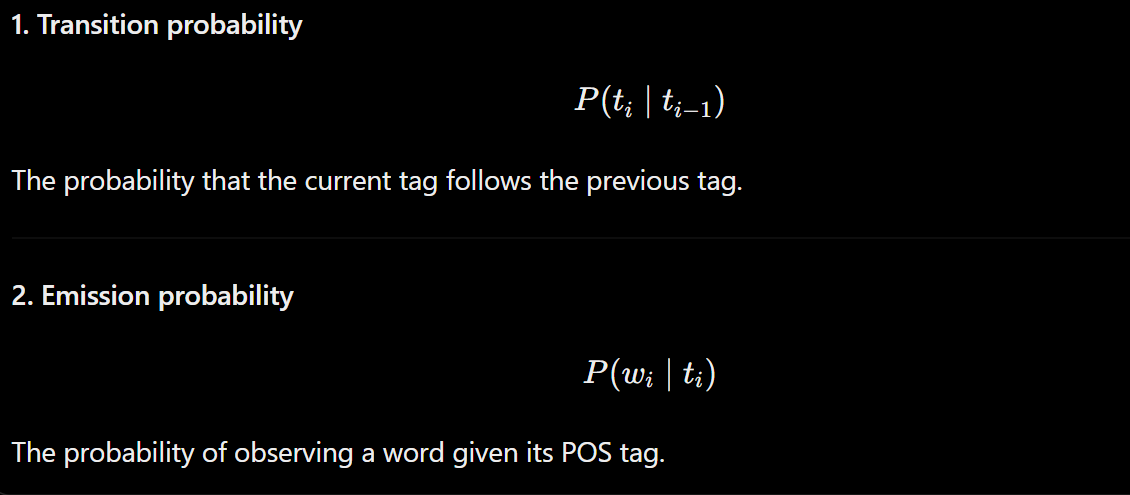
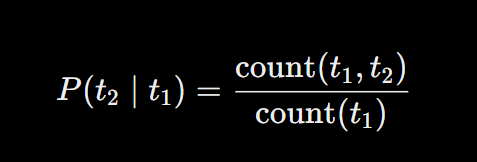
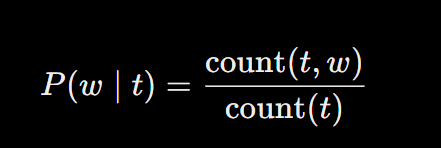

In [7]:
false_prob = 1e-12

transition_prob = {}
for (t1, t2), c in transition_counts.items():
    transition_prob[(t1, t2)] = c / tag_counts[t1] if tag_counts[t1] else false_prob


emission_prob = {}
for (t, w), c in emission_counts.items():
    emission_prob[(t, w)] = c / tag_counts[t] if tag_counts[t] else false_prob


UNK_PROB = false_prob


def emission_p(tag, word):
    key = (tag, word)
    if key in emission_prob:
        return emission_prob[key]
    return UNK_PROB


def transition_p(t1, t2):
    key = (t1, t2)
    if key in transition_prob:
        return transition_prob[key]
    return false_prob

## Forward Viterbi decoding

Standard left-to-right Viterbi trellis and backtracking to predict the most likely tag sequence for a sentence.

In [8]:
def viterbi_forward(words):
    n = len(words)
    viterbi = []
    backpointer = []
    for i, word in enumerate(words):
        curr_v = {}
        curr_b = {}
        if i == 0:
            for t in tag2idx:
                lp = math.log(transition_p(START, t)) + math.log(emission_p(t, word))
                curr_v[t] = lp
                curr_b[t] = START
        else:
            for t in tag2idx:
                best_prev = None
                best_score = None
                for pt in tag2idx:
                    lp = (
                        viterbi[-1][pt]
                        + math.log(transition_p(pt, t))
                        + math.log(emission_p(t, word))
                    )
                    if best_score is None or lp > best_score:
                        best_score = lp
                        best_prev = pt
                curr_v[t] = best_score
                curr_b[t] = best_prev
        viterbi.append(curr_v)
        backpointer.append(curr_b)
    return viterbi, backpointer


def predict_forward(viterbi, backpointer):
    last = viterbi[-1]
    best_tag = max(last, key=last.get)
    tags = []
    tags.append(best_tag)
    for bp in reversed(backpointer[:-1]):
        best_tag = bp[best_tag]
        tags.append(best_tag)
    return list(reversed(tags))

## Backward Viterbi decoding

Right-to-left Viterbi using the end-of-sentence state as the starting point, then reversed backtracking.

In [9]:
def viterbi_backward(words):
    n = len(words)
    rev_words = list(reversed(words))
    viterbi = []
    backpointer = []
    for i, word in enumerate(rev_words):
        curr_v = {}
        curr_b = {}
        if i == 0:
            for t in tag2idx:
                lp = math.log(transition_p(t, END)) + math.log(
                    emission_p(t, word)
                )
                curr_v[t] = lp
                curr_b[t] = END
        else:
            for t in tag2idx:
                best_prev = None
                best_score = None
                for pt in tag2idx:
                    lp = (
                        viterbi[-1][pt]
                        + math.log(transition_p(t, pt))
                        + math.log(emission_p(t, word))
                    )
                    if best_score is None or lp > best_score:
                        best_score = lp
                        best_prev = pt
                curr_v[t] = best_score
                curr_b[t] = best_prev
        viterbi.append(curr_v)
        backpointer.append(curr_b)
    return viterbi, backpointer


def predict_backward(viterbi, backpointer, words):
    first = viterbi[-1]
    best_tag = max(first, key=first.get)
    tags = []
    tags.append(best_tag)
    for bp in reversed(backpointer[:-1]):
        best_tag = bp[best_tag]
        tags.append(best_tag)
    return list(reversed(tags))

## Forward-backward Viterbi decoding

Combine forward and backward trellis probabilities to form a bidirectional Viterbi score for each position and decode the best tag sequence.

In [10]:
def forward_probs(words):
    alpha = []
    for i, word in enumerate(words):
        curr = {}
        if i == 0:
            for t in tag2idx:
                curr[t] = math.log(
                    transition_p(START, t) * emission_p(t, word)
                )
        else:
            for t in tag2idx:
                best_lp = None
                for pt in tag2idx:
                    lp = (
                        alpha[-1][pt]
                        + math.log(transition_p(pt, t))
                        + math.log(emission_p(t, word))
                    )
                    if best_lp is None or lp > best_lp:
                        best_lp = lp
                curr[t] = best_lp
        alpha.append(curr)
    return alpha


def backward_probs(words):
    n = len(words)
    beta = [None] * n
    beta[n - 1] = {}
    for t in tag2idx:
        beta[n - 1][t] = math.log(transition_p(t, END))
    for i in range(n - 2, -1, -1):
        word = words[i + 1]
        curr = {}
        for t in tag2idx:
            best_lp = None
            for pt in tag2idx:
                lp = (
                    beta[i + 1][pt]
                    + math.log(transition_p(t, pt))
                    + math.log(emission_p(pt, word))
                )
                if best_lp is None or lp > best_lp:
                    best_lp = lp
            curr[t] = best_lp
        beta[i] = curr
    return beta


def viterbi_forward_backward(words):
    alpha = forward_probs(words)
    beta = backward_probs(words)
    viterbi = []
    backpointer = []
    for i, word in enumerate(words):
        curr_v = {}
        curr_b = {}
        if i == 0:
            for t in tag2idx:
                lp = alpha[0][t] + beta[0][t] - math.log(
                    emission_p(t, word)
                )
                curr_v[t] = lp
                curr_b[t] = START
        else:
            prev_alpha = alpha[i - 1]
            for t in tag2idx:
                best_prev = None
                best_score = None
                for pt in tag2idx:
                    lp = (
                        prev_alpha[pt]
                        + math.log(transition_p(pt, t))
                        + math.log(emission_p(t, word))
                        + beta[i][t]
                        - math.log(emission_p(t, word))
                    )
                    if best_score is None or lp > best_score:
                        best_score = lp
                        best_prev = pt
                curr_v[t] = best_score
                curr_b[t] = best_prev
        viterbi.append(curr_v)
        backpointer.append(curr_b)
    return viterbi, backpointer

## Evaluation

Evaluate each decoding method on a dataset and compute per-tag precision, recall, F1 and overall accuracy.

In [11]:
def evaluate_dataset(words_list, tags_list, predictor_fn, name):
    pred_all = []
    gold_all = []
    for words, tags in zip(words_list, tags_list):
        pred_tags = predictor_fn(words)
        pred_all.extend(pred_tags)
        gold_all.extend(tags)
    correct_by_tag = Counter()
    gold_by_tag = Counter()
    pred_by_tag = Counter()
    total_correct = 0
    total_tokens = 0
    for g, p in zip(gold_all, pred_all):
        gold_by_tag[g] += 1
        pred_by_tag[p] += 1
        if g == p:
            correct_by_tag[g] += 1
            total_correct += 1
        total_tokens += 1
    accuracy = total_correct / total_tokens if total_tokens else 0.0
    f1_by_tag = {}
    for t in sorted(tags_set):
        tp = correct_by_tag.get(t, 0)
        gold_n = gold_by_tag.get(t, 0)
        pred_n = pred_by_tag.get(t, 0)
        prec = tp / pred_n if pred_n else 0.0
        rec = tp / gold_n if gold_n else 0.0
        f1 = (
            2 * prec * rec / (prec + rec)
            if (prec + rec) > 0
            else 0.0
        )
        f1_by_tag[t] = f1
    return {
        "name": name,
        "accuracy": accuracy,
        "f1_by_tag": f1_by_tag,
        "gold_by_tag": gold_by_tag,
        "pred_by_tag": pred_by_tag,
        "correct_by_tag": correct_by_tag,
    }


predict_forward_fn = lambda ws: predict_forward(
    *viterbi_forward(ws)
)
predict_backward_fn = lambda ws: predict_backward(
    *viterbi_backward(ws), ws
)
predict_fb_fn = lambda ws: predict_forward(
    *viterbi_forward_backward(ws)
)


def nb_predict_sentence_eval(words):
    prev_words = ["<s>"] + words[:-1]
    next_words = words[1:] + ["</s>"]
    prev_tags = ["<s>"] + ["<unknown>"] * (len(words) - 1)
    pred = []
    for i, w in enumerate(words):
        feat = (
            word_length_feat(w),
            w,
            prev_words[i],
            next_words[i],
            prev_tags[i],
        )
        pred.append(nb_predict_one(feat))
    return pred


predict_nb_fn = lambda ws: nb_predict_sentence_eval(ws)


## Development set results

Run all three HMM decoders on the dev set and print accuracy and F1 per tag.

In [12]:
dev_fwd = evaluate_dataset(dev_words, dev_tags, predict_forward_fn, "Forward Viterbi")
dev_bwd = evaluate_dataset(dev_words, dev_tags, predict_backward_fn, "Backward Viterbi")
dev_fb = evaluate_dataset(dev_words, dev_tags, predict_fb_fn, "Forward-Backward Viterbi")
dev_nb = evaluate_dataset(dev_words, dev_tags, predict_nb_fn, "Naive Bayes")


print("Development Set")
for res in [dev_fwd, dev_bwd, dev_fb, dev_nb]:
    print(res["name"])
    print("Accuracy:", res["accuracy"])
    print("F1 by tag:")
    for t in sorted(tags_set):
        print("  ", t, res["f1_by_tag"][t])
    print()


Development Set
Forward Viterbi
Accuracy: 0.15033609734556694
F1 by tag:
   CC_CCD 0.0
   CC_CCS 0.015717092337917484
   DM_DMD 0.0
   JJ 0.03690648973667841
   N_NN 0.09759299781181618
   N_NNP 0.326530612244898
   N_NST 0.0016051364365971107
   PR_PRF 0.006578947368421052
   PR_PRL 0.0
   PR_PRP 0.061689449702068
   PR_PRQ 0.0
   PSP 0.0798467338236203
   QT_QTC 0.11857229280096794
   QT_QTF 0.015360983102918585
   QT_QTO 0.0
   RB 0.005830903790087464
   RD_PUNC 0.7505038291011688
   RD_SYM 0.027700831024930747
   RP_INJ 0.0
   RP_INTF 0.0
   RP_NEG 0.0
   RP_RPD 0.012509773260359656
   V_VAUX 0.3694898464586429
   V_VM 0.03823944565635827

Backward Viterbi
Accuracy: 0.13998331779598647
F1 by tag:
   CC_CCD 0.053921568627450976
   CC_CCS 0.03412073490813648
   DM_DMD 0.02197802197802198
   JJ 0.09119562933389368
   N_NN 0.23543227826865
   N_NNP 0.14925044091710757
   N_NST 0.030534351145038163
   PR_PRF 0.07382550335570469
   PR_PRL 0.03864734299516908
   PR_PRP 0.0556745182012848


## Test set results

Run all three HMM decoders on the held-out test set and print accuracy and F1 per tag.

In [13]:
test_fwd = evaluate_dataset(test_words, test_tags, predict_forward_fn, "Forward Viterbi")
test_bwd = evaluate_dataset(test_words, test_tags, predict_backward_fn, "Backward Viterbi")
test_fb = evaluate_dataset(test_words, test_tags, predict_fb_fn, "Forward-Backward Viterbi")
test_nb = evaluate_dataset(test_words, test_tags, predict_nb_fn, "Naive Bayes")


print("Test Set")
for res in [test_fwd, test_bwd, test_fb, test_nb]:
    print(res["name"])
    print("Accuracy:", res["accuracy"])
    print("F1 by tag:")
    for t in sorted(tags_set):
        print("  ", t, res["f1_by_tag"][t])
    print()


Test Set
Forward Viterbi
Accuracy: 0.15405046480743692
F1 by tag:
   CC_CCD 0.0
   CC_CCS 0.014745308310991957
   DM_DMD 0.0018885741265344666
   JJ 0.0329764453961456
   N_NN 0.09979053654868683
   N_NNP 0.3294622816434078
   N_NST 0.001598721023181455
   PR_PRF 0.006644518272425249
   PR_PRL 0.0
   PR_PRP 0.06212574850299401
   PR_PRQ 0.0
   PSP 0.0759143407122233
   QT_QTC 0.13518406759203377
   QT_QTF 0.006153846153846154
   QT_QTO 0.0
   RB 0.0
   RD_PUNC 0.7489211455472733
   RD_SYM 0.015102481121898598
   RP_INJ 0.0
   RP_INTF 0.0
   RP_NEG 0.0
   RP_RPD 0.004922067268252665
   V_VAUX 0.3929017745563609
   V_VM 0.03655009203260584

Backward Viterbi
Accuracy: 0.1331884582880599
F1 by tag:
   CC_CCD 0.024771838331160367
   CC_CCS 0.03753351206434316
   DM_DMD 0.023099133782483156
   JJ 0.07563573136274723
   N_NN 0.2233228771118816
   N_NNP 0.144573488185823
   N_NST 0.04064352243861135
   PR_PRF 0.0472972972972973
   PR_PRL 0.02185792349726776
   PR_PRP 0.03822629969418961
   PR_

## Summary tables

Build pandas summary tables of F1, gold, predicted and correct counts per tag for each algorithm, and save CSV outputs for dev and test.

In [14]:
def build_summary_table(results_list):
    rows = []
    for r in results_list:
        for t in sorted(tags_set):
            rows.append(
                {
                    "Algorithm": r["name"],
                    "Tag": t,
                    "F1": r["f1_by_tag"][t],
                    "Gold": r["gold_by_tag"].get(t, 0),
                    "Predicted": r["pred_by_tag"].get(t, 0),
                    "Correct": r["correct_by_tag"].get(t, 0),
                }
            )
    return rows


import pandas as pd

dev_rows = build_summary_table([dev_fwd, dev_bwd, dev_fb])
test_rows = build_summary_table([test_fwd, test_bwd, test_fb])


dev_df = pd.DataFrame(dev_rows)
test_df = pd.DataFrame(test_rows)


dev_df
test_df


dev_df.to_csv("results/dev_pos_results.csv", index=False)
test_df.to_csv("results/test_pos_results.csv", index=False)

## Summary tables for all algorithms

Combine Naive Bayes with the three Viterbi variants into the dev and test summary tables and save CSVs. Naive Bayes is included as an additional algorithm.

In [15]:
dev_rows = build_summary_table([dev_fwd, dev_bwd, dev_fb, dev_nb])
test_rows = build_summary_table([test_fwd, test_bwd, test_fb, test_nb])


dev_df = pd.DataFrame(dev_rows)
test_df = pd.DataFrame(test_rows)


dev_df
test_df


dev_df.to_csv("results/dev_pos_results.csv", index=False)
test_df.to_csv("results/test_pos_results.csv", index=False)


## F1 charts

Plot grouped bar charts comparing F1 per tag across the three Viterbi variants for dev and test sets.

In [16]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def plot_tag_f1(df, dataset_name):
    tags = sorted(tags_set)
    algos = ["Forward Viterbi", "Backward Viterbi", "Forward-Backward Viterbi"]
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(tags))
    width = 0.25
    for i, algo in enumerate(algos):
        sub = df[df["Algorithm"] == algo].set_index("Tag").reindex(tags)
        f1s = [sub.loc[t, "F1"] for t in tags]
        ax.bar(x + (i - 1) * width, f1s, width, label=algo, color=colors[i])
    ax.set_xticks(x)
    ax.set_xticklabels(tags, rotation=45, ha="right")
    ax.set_ylabel("F1 score")
    ax.set_title(f"{dataset_name}: F1 per tag by algorithm")
    ax.legend()
    plt.tight_layout()
    path = f"results/{dataset_name.lower().replace(' ', '_')}_f1_chart.png"
    plt.savefig(path, dpi=150)
    print("Saved:", path)


plot_tag_f1(dev_df, "Development")
plot_tag_f1(test_df, "Test")

Saved: results/development_f1_chart.png
Saved: results/test_f1_chart.png


In [17]:
def plot_tag_f1_all(df, dataset_name):
    tags = sorted(tags_set)
    algos = [
        "Naive Bayes",
        "Forward Viterbi",
        "Backward Viterbi",
        "Forward-Backward Viterbi",
    ]
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(tags))
    width = 0.2
    for i, algo in enumerate(algos):
        sub = df[df["Algorithm"] == algo].set_index("Tag").reindex(tags)
        f1s = [sub.loc[t, "F1"] for t in tags]
        ax.bar(x + (i - 1.5) * width, f1s, width, label=algo, color=colors[i])
    ax.set_xticks(x)
    ax.set_xticklabels(tags, rotation=45, ha="right")
    ax.set_ylabel("F1 score")
    ax.set_title(f"{dataset_name}: F1 per tag by algorithm")
    ax.legend()
    plt.tight_layout()
    path = f"results/{dataset_name.lower().replace(' ', '_')}_f1_chart.png"
    plt.savefig(path, dpi=150)
    print("Saved:", path)


plot_tag_f1_all(dev_df, "Development")
plot_tag_f1_all(test_df, "Test")


Saved: results/development_f1_chart.png
Saved: results/test_f1_chart.png


## Save model

Pickle the trained HMM (mappings, transition/emission probabilities, tag counts) for reuse.

## Save Naive Bayes model

Pickle the Naive Bayes model (tag counts, feature conditional counts, prior/likelihood smoothing, tag inventory, feature vocabulary sizes) for reuse.

In [18]:
with open("models/nb_model.pkl", "wb") as f:
    pickle.dump(
        {
            "nb_tag_counts": dict(nb_tag_counts),
            "nb_feat_cond_counts": {t: dict(nb_feat_cond_counts[t]) for t in nb_feat_cond_counts},
            "nb_feat_vocabs": nb_feat_vocabs,
            "nb_tag_total": nb_tag_total,
            "nb_num_tags": nb_num_tags,
            "NB_PRIOR_SMOOTH": NB_PRIOR_SMOOTH,
            "NB_LIKELIHOOD_SMOOTH": NB_LIKELIHOOD_SMOOTH,
        },
        f,
    )


print("Saved Naive Bayes model to models/nb_model.pkl")


Saved Naive Bayes model to models/nb_model.pkl


In [19]:
with open("models/hmm_model.pkl", "wb") as f:
    pickle.dump(
        {
            "word2idx": word2idx,
            "idx2word": idx2word,
            "tag2idx": tag2idx,
            "idx2tag": idx2tag,
            "transition_prob": transition_prob,
            "emission_prob": emission_prob,
            "tag_counts": tag_counts,
        },
        f,
    )


print("Saved HMM model to models/hmm_model.pkl")

Saved HMM model to models/hmm_model.pkl
